In [96]:
import mindmap as mm
import numpy as np
import pandas as pd
import pygsp
import pyvista as pv 

In [97]:
################## Parameters #####################
fconfig = "../../papers/spike/configuration.yml"
sub     = 25
###################################################

reader = mm.io.dataset_reader(fconfig)
mm_dir = reader.config["MM_DIR"]

data = reader(sub, "src", "parc", "white", "cras")
std  = reader.standards("conn")

DATA SUMMARY
Dataset: spike
Subject: sub-pat25
Retrieved objects:
- parc
- src
- cras
- white
Missing objects:
DATA SUMMARY
Dataset: spike
Subject: Standards
Retrieved objects:
- conn
Missing objects:


In [98]:
def correct_labels(labels, sources, parcel):
    """
    Correct labels that misplace left and right hemisphere dipoles because the parcellation is not perfect.
    """
    # map to switch from label id to label name
    clut = parcel.get_clut()
    map  = pd.Series(clut["Label name"].values, index=clut["#No."]).to_dict()
    
    label_names = [map[id] for id in labels]

    # left/right hemisphere seperation
    split = len(sources[0]["vertno"])

    # switch 'lh' labels in right hemisphere to 'rh' homologue and vice virsa
    label_names[:split] = [l.replace("-rh-", "-lh-") for l in label_names[:split]]
    label_names[split:] = [l.replace("-lh-", "-rh-") for l in label_names[split:]]

    # convert back to lable ids
    new_labels = [list(map.keys())[list(map.values()).index(n)] for n in label_names]

    return new_labels

#### ⚙️ **<font color=green>Preprocess Atlas</font>**

🛠️ **<font color=violet>Thresholds</font>**:
- `cons_thresh`: Consistency threshold. Number of subjects that have the connection over total number of subjects (60).
- `len_thresh`: Fiber length threshold.
- `n_thresh`: Number of fibers threshold.

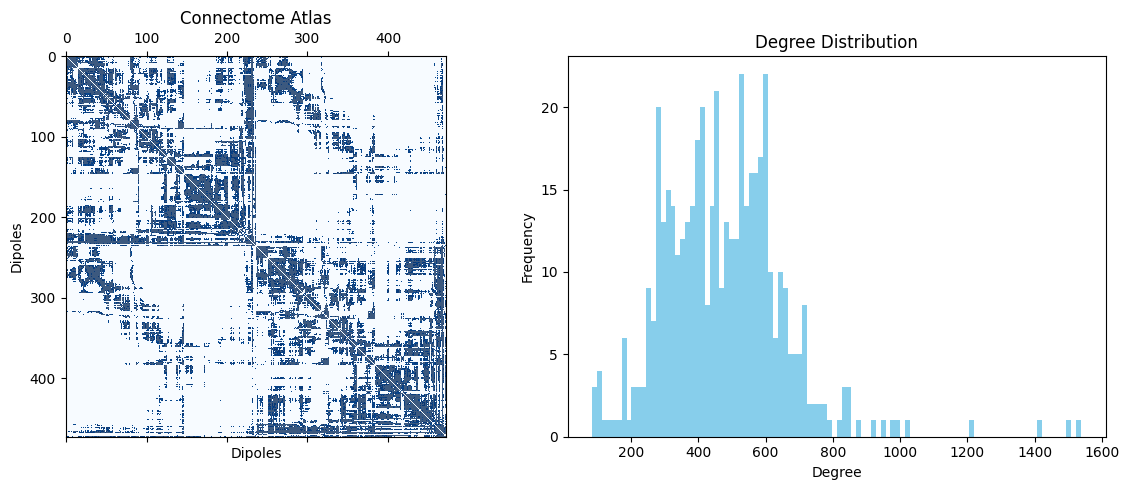

In [92]:
#################### Parameters ##################
# Thresholds
cons_thresh = 40
len_thresh  = 15
n_thresh    = 0
##################################################

# label sources
pos    = mm.utils.get_src_position(data["src"])
pos    = pos*1000 + data["cras"]                   # in surface RAS space in [mm].  !!!!!!! Add the cras translation now that I now  !!!!!!!
labels = data["parc"].label_points(pos, id=True)   # brain region label for each source.

# some left/right regions are very close and get mixed up
labels = correct_labels(labels, data["src"], data["parc"])

# convert atlas to binary adjacency matrix
consistency = std["conn"]["matrices"]["consistency"][:,:]
length      = std["conn"]["matrices"]["length"][:,:]
number      = std["conn"]["matrices"]["numbStlines"][:,:]

consistency = np.nan_to_num(consistency)
length      = np.nan_to_num(length)
number      = np.nan_to_num(number)

regions = std["conn"]["header"]["gmcoords"][:]

sc_atlas = np.bitwise_and(
    consistency > cons_thresh, 
    length > len_thresh,
)
sc_atlas = np.bitwise_and(
    sc_atlas,
    number > n_thresh,
)
sc_atlas = consistency * sc_atlas
#sc_atlas = np.nan_to_num(sc_atlas)

mm.viz.plot_connectome(np.log((sc_atlas)+1), name="Connectome Atlas")

In [93]:
G = pygsp.graphs.Graph(sc_atlas>0, lap_type="normalized", coords=regions)
G.compute_fourier_basis()

cst = G.U.T
U2plot_atlas = G.U

In [101]:
labs    = std["conn"]["header"]["gmcodes"][:]
signals = [cst[i,:][np.array(labels)-1] for i in range(4)]

max_abs = np.max(np.abs(cst[:4,:]))
p = mm.viz.plot_brain(data["src"], signals, cmap="bwr", clim=[-max_abs, max_abs])
p.show()


Widget(value='<iframe src="http://localhost:34441/index.html?ui=P_0x7aff9ab8bc10_17&reconnect=auto" class="pyv…